In [134]:
import numpy as np
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, random_split
from pathlib import Path
import json 

In [135]:
K = 32
R = 40
BATCH = 128
EPOCHS = 50
LR = 3e-4
SEED = 580

Datasets_Paths = [
    "kaleidoscope",
    "lissajous",
    "rose",
    "spiro",
    "truchet"
]
FAMILY = "spiro"

In [136]:
DATA_DIR = Path("../../Data/GeneratedData")

def load_family(name):
    with open(DATA_DIR / f"{name}.json", "r", encoding="utf-8") as f:
        return json.load(f)
        
        
def split_samples(samples, val_frac=0.2, seed=580):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(samples))
    n_val = int(len(samples) * val_frac)
    val = [samples[i] for i in idx[:n_val]]
    train = [samples[i] for i in idx[n_val:]]
    return train, val

if FAMILY not in Datasets_Paths:
    raise ValueError(f"Unknown family {FAMILY!r}; choose from {Datasets_Paths}")

samples = load_family(FAMILY)
train_samples, val_samples = split_samples(samples)
print(len(train_samples), "train drawings,", len(val_samples), "val drawings")

600 train drawings, 150 val drawings


In [137]:
def seq_distance(sample):
    pts = np.vstack([np.asarray(s, dtype=np.float32) for s in sample["strokes"]])
    d = np.diff(pts, axis=0, prepend=pts[:1])
    pen = np.zeros(len(pts), dtype=np.float32)
    idx = 0
    for s in sample["strokes"]:
        idx += len(s)
        pen[idx - 1] = 1.0
    return np.column_stack([d, pen, pts]).astype(np.float32)

train_rows = [seq_distance(s) for s in train_samples]

DELTA_SCALE = np.vstack([r[:, :2] for r in train_rows]).std(0)
POS_SCALE = np.vstack([r[:, 3:5] for r in train_rows]).std(0)

print("DELTA_SCALE:", DELTA_SCALE)
print("POS_SCALE:", POS_SCALE)


def scale_rows(rows):
    out = rows.copy()
    out[:, :2] /= DELTA_SCALE
    out[:, 3:5] /= POS_SCALE
    return out


def make_rollout_windows(rows_list, k=K, r=R, S=4):
    X, Y = [], []
    for rows in rows_list:
        rows = scale_rows(rows)
        for i in range(0, len(rows) - k - r, S):
            X.append(rows[i:i + k])
            Y.append(rows[i + k:i + k + r])
    return torch.tensor(np.array(X)), torch.tensor(np.array(Y))

DELTA_SCALE: [0.00722128 0.00721109]
POS_SCALE: [0.53561586 0.51767606]


In [138]:
## DATA CELLZ

X_train, Y_train = make_rollout_windows(train_rows)
X_val, Y_val = make_rollout_windows([seq_distance(s) for s in val_samples])

print("train windows:", len(X_train), "val windows:", len(X_val))
print("Y_train delta std per axis:", Y_train[..., :2].std(dim=(0, 1)))

train_loader = DataLoader(
    TensorDataset(X_train, Y_train),
    batch_size=BATCH,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    TensorDataset(X_val, Y_val),
    batch_size=BATCH,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

train windows: 289200 val windows: 72300
Y_train delta std per axis: tensor([0.9989, 1.0113])


In [139]:
class LSTM_Model(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim):
        super(LSTM_Model, self).__init__()
        self.hidden_dim = hidden_dim
        self.layer_dim = layer_dim 
        self.lstm = nn.LSTM(input_dim, hidden_dim, layer_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        output = self.fc(lstm_out[:, -1, :])  # Get the last time step's output
        return output

def Loss_Calc(pred, target):
    xy = mse(pred[:, :2], target[:, :2])
    pen = bce(pred[:, 2], target[:, 2])
    return xy + pen 

def rollout_loss(model, x, y, drift_w=1.0):
    window = x
    pos_step = torch.tensor(DELTA_SCALE / POS_SCALE, dtype=torch.float32)
    total = 0.0 
    pred_sum = torch.zeros(x.shape[0], 2)
    tgt_sum = torch.zeros(x.shape[0], 2)
    for r in range(y.shape[1]):
        pred = model(window)
        total = total + Loss_Calc(pred, y[:, r], )
        pred_sum = pred_sum + pred[:, :2]
        tgt_sum = tgt_sum + y[:, r, :2]
        pen = torch.sigmoid(pred[:, 2:3])
        pos = window[:, -1, 3:5] + pred[:, :2] * pos_step
        step = torch.cat([pred[:, :2], pen, pos], dim=1).unsqueeze(1)
        window = torch.cat([window[:, 1:], step], dim=1)
    drift = mse(pred_sum, tgt_sum) / (y.shape[1] ** 2)
    return total / y.shape[1] + drift_w * drift


In [ ]:
model = LSTM_Model(input_dim=5, hidden_dim=64, layer_dim=3, output_dim=3)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
mse = nn.MSELoss()
bce = nn.BCEWithLogitsLoss()



In [141]:


for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0 

    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = rollout_loss(model, xb, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item() * len(xb)
    train_loss/= len(X_train)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            val_loss += rollout_loss(model, xb, yb).item() * len(xb)
    val_loss /= len(X_val)

    print(f"| Epoch {epoch+1}/{EPOCHS}   |    Train_Loss:    {train_loss:.4f}   |   Val_Loss:  {val_loss:.4f}")

| Epoch 1/50   |    Train_Loss:    0.4170   |   Val_Loss:  0.2244
| Epoch 2/50   |    Train_Loss:    0.1324   |   Val_Loss:  0.1229
| Epoch 3/50   |    Train_Loss:    0.0938   |   Val_Loss:  0.0784
| Epoch 4/50   |    Train_Loss:    0.0722   |   Val_Loss:  0.0586
| Epoch 5/50   |    Train_Loss:    0.0555   |   Val_Loss:  0.0581
| Epoch 6/50   |    Train_Loss:    0.0424   |   Val_Loss:  0.0574
| Epoch 7/50   |    Train_Loss:    0.0357   |   Val_Loss:  0.0400
| Epoch 8/50   |    Train_Loss:    0.0299   |   Val_Loss:  0.0287
| Epoch 9/50   |    Train_Loss:    0.0268   |   Val_Loss:  0.0251
| Epoch 10/50   |    Train_Loss:    0.0231   |   Val_Loss:  0.0348
| Epoch 11/50   |    Train_Loss:    0.0204   |   Val_Loss:  0.0248
| Epoch 12/50   |    Train_Loss:    0.0186   |   Val_Loss:  0.0202
| Epoch 13/50   |    Train_Loss:    0.0168   |   Val_Loss:  0.0157
| Epoch 14/50   |    Train_Loss:    0.0151   |   Val_Loss:  0.0167
| Epoch 15/50   |    Train_Loss:    0.0140   |   Val_Loss:  0.0130
| Ep

In [142]:
def generate(model, seed_window, steps=300):
    model.eval()
    window = seed_window.clone()
    pos = window[:, -1, 3:5].clone()
    delta_step = torch.as_tensor(
        DELTA_SCALE / POS_SCALE, dtype=window.dtype, device=window.device
    )
    pos_scale = torch.as_tensor(POS_SCALE, dtype=window.dtype, device=window.device)
    out, path = [], []
    with torch.no_grad():
        for _ in range(steps):
            pred = model(window)
            pen = torch.sigmoid(pred[:, 2:3])
            pos = pos + pred[:, :2] * delta_step
            row = torch.cat([pred[:, :2], pen, pos], dim=1)
            out.append(row.squeeze(0).cpu().numpy())
            path.append((pos * pos_scale).squeeze(0).cpu().numpy())
            window = torch.cat([window[:, 1:, :], row.unsqueeze(1)], dim=1)
    return np.asarray(out), np.asarray(path)

In [143]:
def split_by_pen(path, pen):
    strokes, cur = [], []
    for p, flag in zip(path, pen):
        cur.append(p)
        if flag  > 0.5: 
            strokes.append(np.array(cur))
            cur = []
    if cur:
        strokes.append(np.array(cur))
    return strokes

In [144]:
val_rows = scale_rows(seq_distance(val_samples[0]))
seed = torch.tensor(val_rows[:K]).unsqueeze(0)

In [145]:
print("Y_train delta std per axis:", Y_train[..., :2].std(dim=(0, 1)))
print("X_train delta std per axis:", X_train[..., :2].std(dim=(0, 1)))

Y_train delta std per axis: tensor([0.9989, 1.0113])
X_train delta std per axis: tensor([0.9962, 1.0105])


In [146]:
with torch.no_grad():
    pred = model(X_val)
print("pred delta std:", pred[:, :2].std(0), "target next-step std:", Y_val[:, 0, :2].std(0))

pred delta std: tensor([0.9930, 0.9984]) target next-step std: tensor([0.9905, 1.0004])


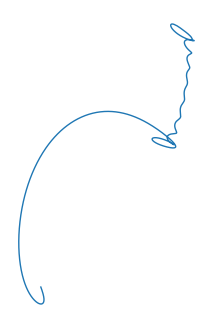

In [147]:
real_pts = np.vstack([np.asarray(s, dtype=np.float32) for s in val_samples[0]["strokes"]])

generated, path = generate(model, seed, steps=max(0, len(real_pts) - K))
seed_path = val_rows[:K, 3:5] * POS_SCALE
generated_path = np.vstack([seed_path, path])
generated_pen = np.concatenate([val_rows[:K, 2], generated[:, 2]])
gen_strokes = split_by_pen(generated_path, generated_pen)

fig, ax = plt.subplots(figsize=(4, 4))
for s in gen_strokes:
    ax.plot(s[:, 0], s[:, 1], lw=1)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [148]:
print("generated rows:", generated.shape)
print("pen-up steps:", int((generated[:, 2] > 0.5).sum()), "out of", len(generated))
print("x range:", path[:, 0].min(), path[:, 0].max())
print("y range:", path[:, 1].min(), path[:, 1].max())

generated rows: (1968, 5)
pen-up steps: 0 out of 1968
x range: 0.38295797 0.9051619
y range: -0.7846444 0.048895806


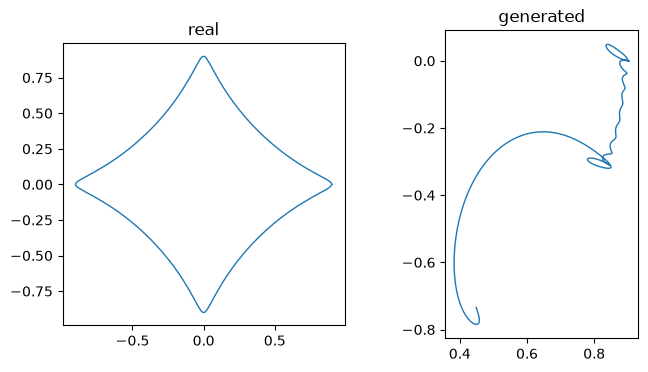

In [149]:
real = np.vstack([np.asarray(s, dtype=np.float32) for s in val_samples[0]["strokes"]])
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(real[:, 0], real[:, 1], lw=1); ax[0].set_title("real")
for s in gen_strokes:
    ax[1].plot(s[:, 0], s[:, 1], lw=1)
ax[1].set_title("generated")
for a in ax:
    a.set_aspect("equal")
plt.show()

In [150]:
n_real = len(real_pts)
steps = max(0, n_real - K)
generated, path = generate(model, seed, steps=steps)
if path.size and len(val_samples[0]["strokes"]) == 1:
    gap = np.linalg.norm(path[-1] - real_pts[0])
    print("end-to-start gap:", gap)
else:
    print("end-to-start gap: n/a for multi-stroke curves")
print("generated points:", len(path))
print("x range:", path[:, 0].min(), path[:, 0].max())
print("y range:", path[:, 1].min(), path[:, 1].max())

end-to-start gap: 0.86184776
generated points: 1968
x range: 0.38295797 0.9051619
y range: -0.7846444 0.048895806


In [151]:
print("real x range:", real_pts[:, 0].min(), real_pts[:, 0].max())
print("generated x range:", path[:, 0].min(), path[:, 0].max())
print("generated mean x step:", (generated[:, 0] * DELTA_SCALE[0]).mean())

real x range: -0.9 0.9
generated x range: 0.38295797 0.9051619
generated mean x step: -0.00022373564


In [152]:
with torch.no_grad():
    p = model(X_val)
print("pred x mean:", p[:, 0].mean().item(), "target x mean:", Y_val[:, 0, 0].mean().item())

pred x mean: 0.0003898241266142577 target x mean: -0.0055734701454639435
